# 01. Deep EDA: Kelompok Sayuran & Bumbu Dapur (Hortikultura)
## Proyek: HargaWatch Surabaya — Platform Intelijen Harga Pangan & Early Warning System

---

### Konteks Domain: *Volatile Foods*
Kelompok Sayuran dan Bumbu Dapur (Hortikultura) merupakan komponen pangan dengan **tingkat volatilitas tertinggi (*Volatile Foods*)** di pasar tradisional Surabaya. Karakteristik utama kelompok ini:
1. **Perishable (Sangat Mudah Busuk)**: Umur simpan pendek tanpa teknologi *cold-chain* terintegrasi di pasar tradisional, sehingga harga sangat sensitif terhadap gangguan logistik harian.
2. **Ketergantungan Pasokan Luar Daerah**: Surabaya adalah kota metropolitan non-produsen; pasokan cabai dan bawang 100% dipasok dari sentra agronomis Jawa Timur (Kediri, Nganjuk, Probolinggo, Blitar, Malang, Banyuwangi).
3. **Penyumbang Utama Volatilitas Inflasi**: Komoditas seperti **Cabe Rawit Merah (ID 50)** dan **Bawang Merah (ID 39)** merupakan penyumbang utama inflasi bulanan (*volatile food inflation*).

### Komoditas yang Dianalisis (10 Komoditas Resmi):
- **Kelompok Cabai**: Cabe Rawit Merah (ID 50 - Target Utama Champion LightGBM), Cabe Merah Besar (ID 38), Cabe Merah Keriting (ID 37).
- **Kelompok Bawang**: Bawang Merah (ID 39 - Target Champion CatBoost), Bawang Putih Sinco/Honan (ID 49).
- **Sayur Mayur**: Tomat Merah (ID 46), Buncis (ID 48), Kentang (ID 45), Kol/Kubis (ID 44), Wortel (ID 47).

### Analisis Deret Waktu & Keputusan Sistem (Decision Map):
- **Dekomposisi Time Series**: `seasonal_decompose` (Trend, Seasonal, Residual) & Analisis ACF/PACF (`plot_acf`, `plot_pacf`).
- **D4**: Apakah terdapat efek *weekend* signifikan pada komoditas hortikultura?
- **D5**: Seberapa besar magnitude shock pra-Ramadan (H-14) & Ramadan pada harga cabai dan bawang?
- **D6**: Bagaimana pola musiman bulanan (siklus panen raya vs paceklik Jawa Timur)?
- **D7**: Apakah libur nasional non-keagamaan memicu lonjakan harga signifikan?
- **D8**: Apakah curah hujan lokal Surabaya berkorelasi dengan harga hortikultura (validasi keputusan ablasi fitur)?
- **D9**: Bagaimana posisi data produsen lokal untuk kelompok hortikultura di Surabaya?
- **D12 & D15**: Bagaimana transmisi harga dan lead-lag Pasar Induk Keputran (ID 5) terhadap pasar ritel?
- **D14**: Bagaimana disparitas dan persistensi peringkat harga antar 6 pasar tradisional?


In [1]:
import sys
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

# Mendeteksi project root secara dinamis (berfungsi baik dari root maupun subfolder notebook/)
CURRENT_DIR = Path.cwd().resolve()
PROJECT_ROOT = CURRENT_DIR if (CURRENT_DIR / "src").exists() else CURRENT_DIR.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Ekonometrika & Analisis Deret Waktu (Time Series)
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose

from src.analytics.eda_helpers import (
    load_cleaned_market_data,
    calculate_summary_stats,
    test_stationarity,
    compute_lead_lag_cross_corr,
    calculate_ramadan_impact,
    set_eda_style,
    plot_commodity_time_series,
    plot_market_spread_boxplot,
    plot_acf_pacf_analysis,
    plot_time_series_decomposition
)

# Inisialisasi tema visualisasi terstandar
set_eda_style()
print(f"[SETUP] Root directory: {PROJECT_ROOT}")
print("[SETUP] Library, modul ekonometrika time-series, dan helper terintegrasi dengan sukses.")


[SETUP] Root directory: D:\ARFI\Kuliah\Project\project-semester5\hargawatch-surabaya
[SETUP] Library, modul ekonometrika time-series, dan helper terintegrasi dengan sukses.


## 1. Ingestion Data & Segmentasi Kelompok Hortikultura

Data harga gabungan dimuat bersama dimensi pasar, kalender, dan cuaca historis. Kita menyaring 10 komoditas hortikultura yang terdaftar pada master data.


In [2]:
# Ingestion data pasar gabungan
df_all = load_cleaned_market_data(include_calendar=True, include_weather=True)

# 10 ID Komoditas Hortikultura Resmi
HORTI_IDS = [50, 38, 37, 39, 49, 46, 45, 44, 48, 47]
df_horti = df_all[df_all["komoditas_id"].isin(HORTI_IDS)].copy()

# Ringkasan observasi hortikultura
total_baris = len(df_horti)
rentang_tgl = f"{df_horti['tanggal'].min().strftime('%Y-%m-%d')} s/d {df_horti['tanggal'].max().strftime('%Y-%m-%d')}"
n_komoditas = df_horti["komoditas_id"].nunique()
n_pasar = df_horti["pasar_id"].nunique()

df_summary_ingest = pd.DataFrame([{
    "Total Baris Observasi": f"{total_baris:,}",
    "Jumlah Komoditas": n_komoditas,
    "Jumlah Pasar": n_pasar,
    "Rentang Waktu": rentang_tgl,
    "Total Hari Unik": df_horti["tanggal"].nunique()
}])

display(df_summary_ingest)


  Total Baris Observasi  Jumlah Komoditas  Jumlah Pasar              Rentang Waktu  Total Hari Unik
0               135,949                10             6  2020-01-01 s/d 2026-09-24             2459


,Total Baris Observasi,Jumlah Komoditas,Jumlah Pasar,Rentang Waktu,Total Hari Unik
0,"135,949",10,6,2020-01-01 s/d 2026-09-24,2459


## 2. Univariate Profiling & Ranking Volatilitas (*Coefficient of Variation*)

Pada sistem peramalan harga pangan, nilai absolut standar deviasi tidak adil jika dibandingkan antar komoditas yang berbeda skala harga (misal Cabe Rp 50.000 vs Kol Rp 8.000). Oleh karena itu, kita mengukur rasio volatilitas ternormalisasi menggunakan **Coefficient of Variation (CV)**:

$$CV = \frac{\sigma}{\mu} \times 100\%$$

Komoditas dengan $CV > 30\%$ dikategorikan sebagai *Extremely Volatile*, menuntut arsitektur model Machine Learning yang fleksibel (seperti LightGBM dengan lag dinamis).


             nama_komoditas  Count  Mean (Rp)  Median (Rp)  Std (Rp)  CV (%)  IQR (Rp)  Skewness  Min (Rp)  Max (Rp)
0          Cabe Rawit Merah  13747    44292.0      40000.0   21594.0   48.75   32000.0      0.87   11000.0  145000.0
1          Cabe Merah Besar  13747    35699.0      32000.0   14726.0   41.25   20000.0      1.04   10000.0  140000.0
2       Cabe Merah Keriting  12226    37773.0      35000.0   14457.0   38.27   17000.0      0.84   10000.0  120000.0
3               Tomat Merah  13747    13615.0      12000.0    4884.0   35.88    6000.0      1.02    4000.0   35000.0
4                    BUNCIS  13747    13392.0      12000.0    3334.0   24.89    3000.0      0.83    6000.0   30000.0
5                 KOL/KUBIS  13747     8636.0       8000.0    2131.0   24.68    3000.0      0.72    4000.0   20000.0
6              Bawang Merah  13747    32941.0      32000.0    8086.0   24.55   10000.0      0.80   16000.0   80000.0
7  Bawang Putih Sinco/Honan  13723    30383.0      30000.0    67

,nama_komoditas,Count,Mean (Rp),Median (Rp),Std (Rp),CV (%),IQR (Rp),Skewness,Min (Rp),Max (Rp)
0,Cabe Rawit Merah,13747,44292.0,40000.0,21594.0,48.75,32000.0,0.87,11000.0,145000.0
1,Cabe Merah Besar,13747,35699.0,32000.0,14726.0,41.25,20000.0,1.04,10000.0,140000.0
2,Cabe Merah Keriting,12226,37773.0,35000.0,14457.0,38.27,17000.0,0.84,10000.0,120000.0
3,Tomat Merah,13747,13615.0,12000.0,4884.0,35.88,6000.0,1.02,4000.0,35000.0
4,BUNCIS,13747,13392.0,12000.0,3334.0,24.89,3000.0,0.83,6000.0,30000.0
5,KOL/KUBIS,13747,8636.0,8000.0,2131.0,24.68,3000.0,0.72,4000.0,20000.0
6,Bawang Merah,13747,32941.0,32000.0,8086.0,24.55,10000.0,0.80,16000.0,80000.0
7,Bawang Putih Sinco/Honan,13723,30383.0,30000.0,6705.0,22.07,10000.0,0.17,15000.0,65000.0
8,WORTEL,13747,12328.0,12000.0,2366.0,19.19,4000.0,0.49,6000.0,25000.0
9,KENTANG,13747,15356.0,15000.0,1940.0,12.63,3000.0,0.51,10000.0,25000.0


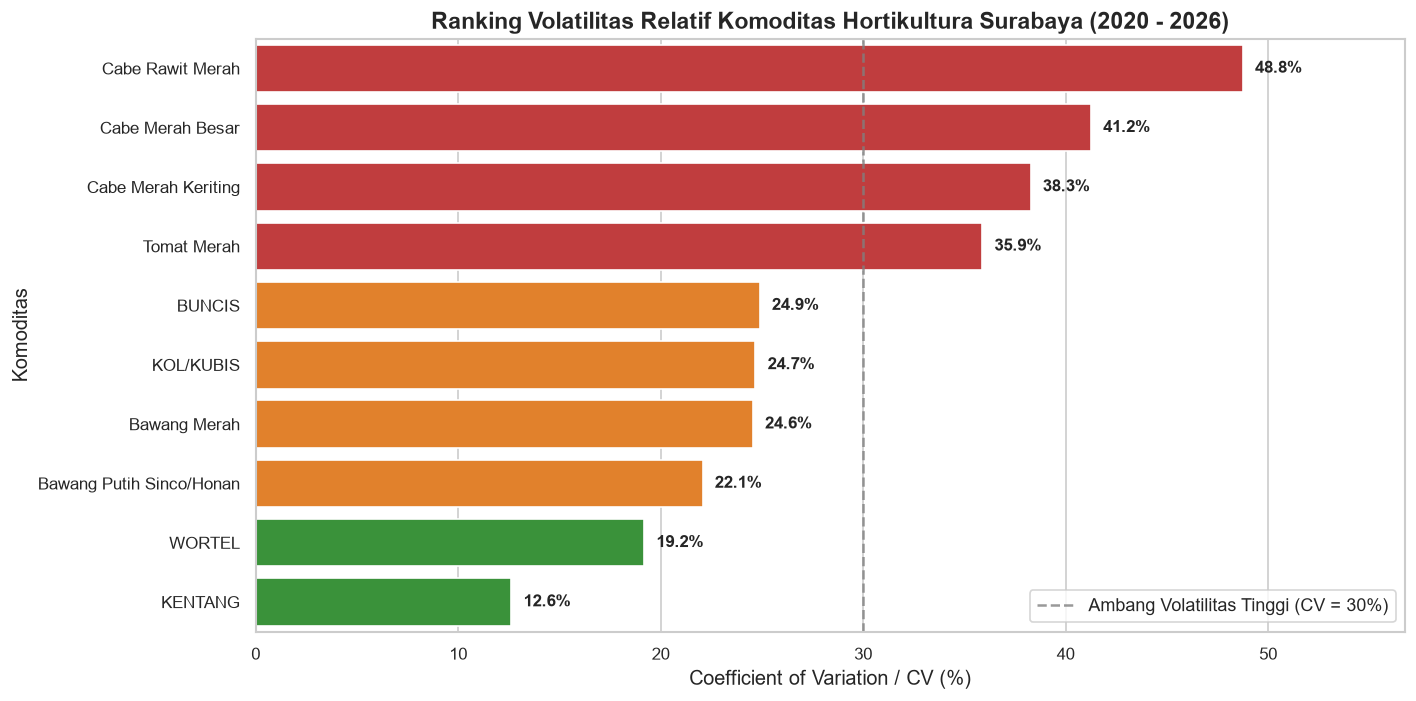

In [3]:
# 1. Hitung Profil Statistik Terstandar
df_stats_horti = calculate_summary_stats(df_horti, group_col="nama_komoditas")
display(df_stats_horti)

# 2. Visualisasi Ranking Volatilitas (CV %)
plt.figure(figsize=(12, 6))
palette_cv = ["#d62728" if cv > 35 else ("#ff7f0e" if cv > 20 else "#2ca02c") for cv in df_stats_horti["CV (%)"]]
ax = sns.barplot(data=df_stats_horti, x="CV (%)", y="nama_komoditas", palette=palette_cv)

plt.axvline(30.0, color="gray", linestyle="--", alpha=0.8, label="Ambang Volatilitas Tinggi (CV = 30%)")
for p in ax.patches:
    width = p.get_width()
    ax.annotate(f"{width:.1f}%", (width + 0.6, p.get_y() + p.get_height() / 2.),
                va="center", ha="left", fontsize=10, fontweight="bold")

plt.title("Ranking Volatilitas Relatif Komoditas Hortikultura Surabaya (2020 - 2026)", fontweight="bold")
plt.xlabel("Coefficient of Variation / CV (%)")
plt.ylabel("Komoditas")
plt.legend(loc="lower right")
plt.xlim(0, max(df_stats_horti["CV (%)"]) + 8)
plt.tight_layout()
plt.show()


## 3. Analisis Time Series Lanjutan: Stasioneritas, ACF/PACF, & Dekomposisi Musiman

Pada peramalan time series, analisis mendalam terhadap struktur autokorelasi dan dekomposisi komponen sangat krusial:
1. **Uji Stasioneritas (ADF & KPSS)**: Memastikan apakah deret membutuhkan differencing ($d=1$).
2. **Autocorrelation Function (ACF)**: Mengukur seberapa lama efek memori/persistensi harga bertahan.
3. **Partial Autocorrelation Function (PACF)**: Mengidentifikasi signifikansi lag langsung ($lag_1, lag_2, lag_7, \dots$) untuk penentuan parameter AR(p) dan feature engineering lag pada model GBDT.
4. **Seasonal Decomposition (`seasonal_decompose`)**: Memisahkan deret harga menjadi:
   - **Trend**: Arah jangka panjang bebas dari siklus musiman tahunan.
   - **Seasonal**: Komponen siklikal periodik reguler (siklus tahunan $365$ hari).
   - **Residual**: Komponen acak atau *unforeseen supply shocks* (misal anomali cuaca ekstrem di sentra produksi).


=== Ringkasan Uji Stasioneritas Ekonometrika ===
          Komoditas  Level ADF p-val  Level KPSS p-val                                   Kesimpulan Level  Diff(1) ADF p-val  Diff(1) KPSS p-val                   Kesimpulan Diff(1)
0  Cabe Rawit Merah           0.0000            0.1000                STATIONARY (No differencing needed)                0.0                 0.1  STATIONARY (No differencing needed)
1      Bawang Merah           0.0000            0.0166  DIFFERENCE-STATIONARY (Possible structural break)                0.0                 0.1  STATIONARY (No differencing needed)
2       Tomat Merah           0.0003            0.1000                STATIONARY (No differencing needed)                0.0                 0.1  STATIONARY (No differencing needed)
Tabel Korelasi Lag (Top 10 Lags Cabe Rawit):
    Lag     ACF    PACF
0     0  1.0000  1.0000
1     1  0.9907  0.9907
2     2  0.9785 -0.1640
3     3  0.9670  0.0603
4     4  0.9557 -0.0168
5     5  0.9437 -0.0368
6     6  0

,Komoditas,Level ADF p-val,Level KPSS p-val,Kesimpulan Level,Diff(1) ADF p-val,Diff(1) KPSS p-val,Kesimpulan Diff(1)
0,Cabe Rawit Merah,0.0000,0.1000,STATIONARY (No differencing needed),0.0,0.1,STATIONARY (No differencing needed)
1,Bawang Merah,0.0000,0.0166,DIFFERENCE-STATIONARY (Possible structural break),0.0,0.1,STATIONARY (No differencing needed)
2,Tomat Merah,0.0003,0.1000,STATIONARY (No differencing needed),0.0,0.1,STATIONARY (No differencing needed)


,Lag,ACF,PACF
0,0,1.0000,1.0000
1,1,0.9907,0.9907
2,2,0.9785,-0.1640
3,3,0.9670,0.0603
4,4,0.9557,-0.0168
5,5,0.9437,-0.0368
6,6,0.9305,-0.0645
7,7,0.9147,-0.1335
8,8,0.8976,-0.0476
9,9,0.8804,-0.0080


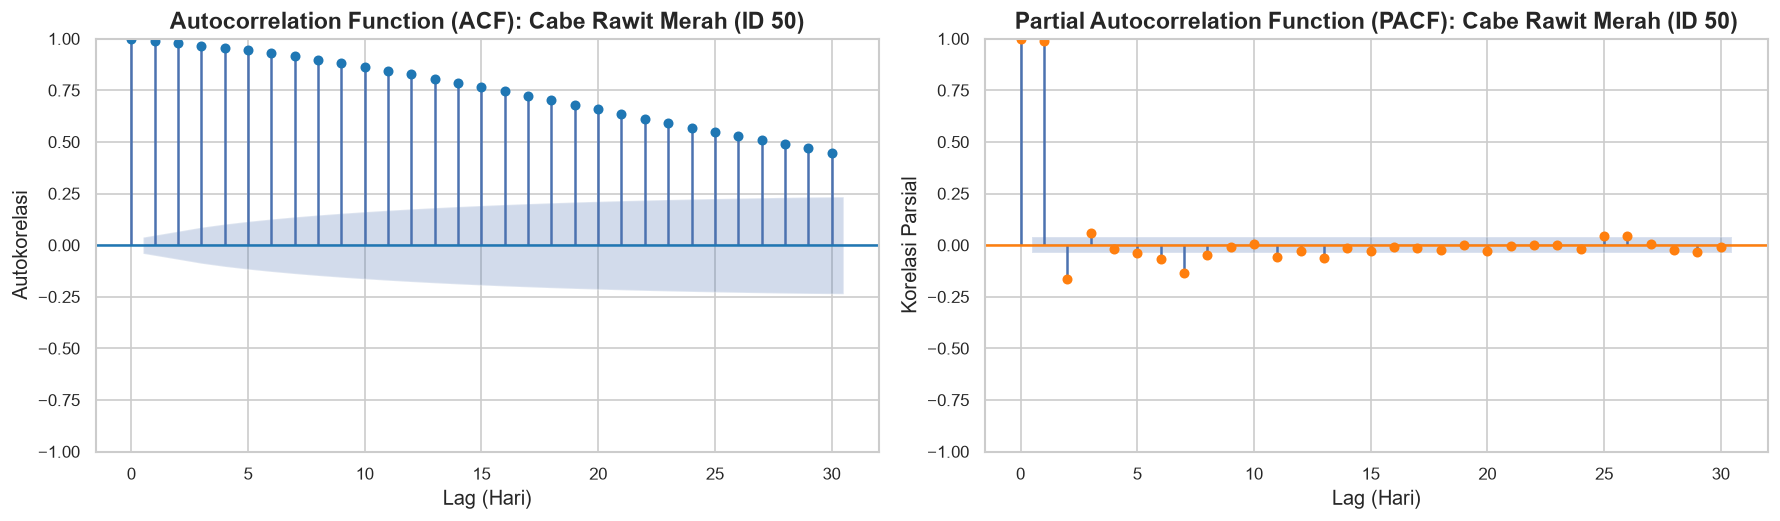

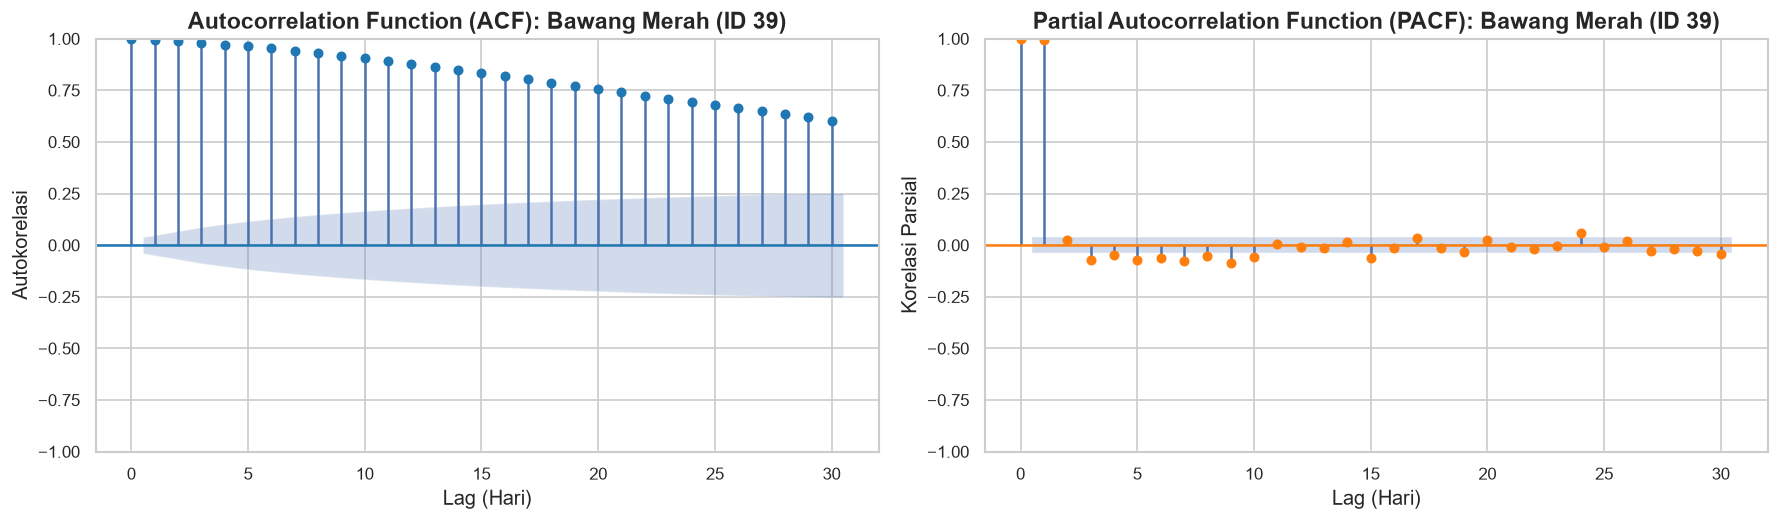

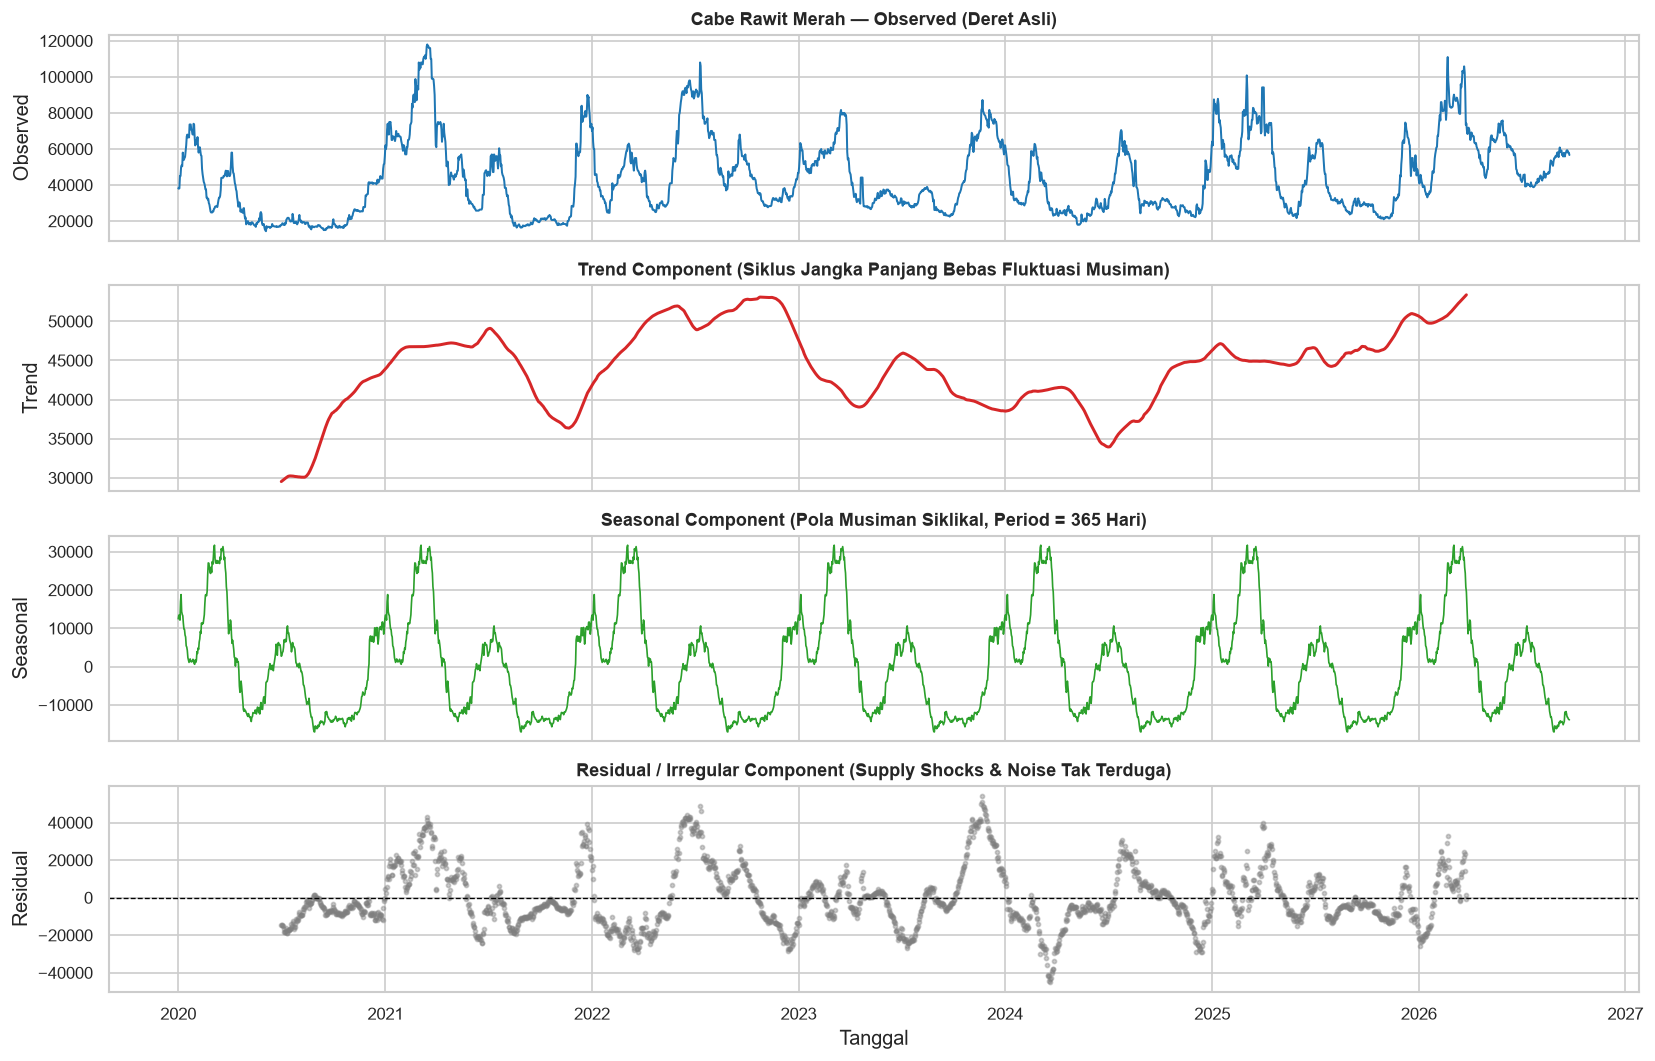

In [4]:
# 3.1 Uji Stasioneritas Level vs First Difference (ADF & KPSS)
stat_records = []
target_test = [(50, "Cabe Rawit Merah"), (39, "Bawang Merah"), (46, "Tomat Merah")]

for cid, name in target_test:
    series_level = df_horti[df_horti["komoditas_id"] == cid].groupby("tanggal")["harga_imputasi"].mean()
    series_diff = series_level.diff().dropna()

    res_lvl = test_stationarity(series_level)
    res_df = test_stationarity(series_diff)

    stat_records.append({
        "Komoditas": name,
        "Level ADF p-val": res_lvl["adf_pvalue"],
        "Level KPSS p-val": res_lvl["kpss_pvalue"],
        "Kesimpulan Level": res_lvl["conclusion"],
        "Diff(1) ADF p-val": res_df["adf_pvalue"],
        "Diff(1) KPSS p-val": res_df["kpss_pvalue"],
        "Kesimpulan Diff(1)": res_df["conclusion"]
    })

df_stat_results = pd.DataFrame(stat_records)
print("=== Ringkasan Uji Stasioneritas Ekonometrika ===")
display(df_stat_results)

# 3.2 Analisis Autokorelasi & Parsial (ACF & PACF) untuk Cabe Rawit Merah
series_cabe = df_horti[df_horti["komoditas_id"] == 50].groupby("tanggal")["harga_imputasi"].mean()
fig_acf, df_lags_cabe = plot_acf_pacf_analysis(series_cabe, nlags=30, title_prefix="Cabe Rawit Merah (ID 50)")
plt.show()

print("Tabel Korelasi Lag (Top 10 Lags Cabe Rawit):")
display(df_lags_cabe.head(11))

# 3.3 Analisis Autokorelasi & Parsial (ACF & PACF) untuk Bawang Merah
series_bawang = df_horti[df_horti["komoditas_id"] == 39].groupby("tanggal")["harga_imputasi"].mean()
fig_acf_b, df_lags_bawang = plot_acf_pacf_analysis(series_bawang, nlags=30, title_prefix="Bawang Merah (ID 39)")
plt.show()

# 3.4 Dekomposisi Musiman (Seasonal Decomposition - Period 365 Hari)
fig_decomp = plot_time_series_decomposition(series_cabe, model="additive", period=365, title_prefix="Cabe Rawit Merah")
plt.show()


## 4. Dekomposisi Temporal & Pola Musiman Kalender

Pola pergerakan harga hortikultura dianalisis melalui 4 dimensi kalender untuk menjawab keputusan sistem:
- **D4 (Weekend Effect)**: Apakah harga Sabtu-Minggu lebih mahal dibandingkan hari kerja?
- **D5 (Ramadan Shock)**: Seberapa besar lonjakan harga pada masa pra-Ramadan (H-14) dan Ramadan?
- **D6 (Pola Musiman Bulanan)**: Bagaimana siklus agronomis bulanan (panen raya vs musim hujan/paceklik)?
- **D7 (Libur Nasional)**: Apakah hari libur nasional non-keagamaan memicu kenaikan harga signifikan?


=== Evaluasi Keputusan D4: Weekend Effect pada 10 Komoditas Hortikultura ===
                  Komoditas  Mean Weekday (Rp)  Mean Weekend (Rp)  Selisih (%)  T-Statistic  p-value Signifikan (alpha=0.05)
0          Cabe Rawit Merah            44292.1            44292.8         0.00       -0.002   0.9986         TIDAK (Identik)
1          Cabe Merah Besar            35758.2            35549.4        -0.58        0.759   0.4479         TIDAK (Identik)
2       Cabe Merah Keriting            37801.7            37701.7        -0.26        0.348   0.7277         TIDAK (Identik)
3              Bawang Merah            32927.1            32974.6         0.14       -0.311   0.7561         TIDAK (Identik)
4  Bawang Putih Sinco/Honan            30360.3            30438.7         0.26          NaN      NaN         TIDAK (Identik)
5               Tomat Merah            13604.8            13639.7         0.26       -0.377   0.7062         TIDAK (Identik)
6                   KENTANG            15353.7  

,Komoditas,Mean Weekday (Rp),Mean Weekend (Rp),Selisih (%),T-Statistic,p-value,Signifikan (alpha=0.05)
0,Cabe Rawit Merah,44292.1,44292.8,0.00,-0.002,0.9986,TIDAK (Identik)
1,Cabe Merah Besar,35758.2,35549.4,-0.58,0.759,0.4479,TIDAK (Identik)
2,Cabe Merah Keriting,37801.7,37701.7,-0.26,0.348,0.7277,TIDAK (Identik)
3,Bawang Merah,32927.1,32974.6,0.14,-0.311,0.7561,TIDAK (Identik)
4,Bawang Putih Sinco/Honan,30360.3,30438.7,0.26,NaN,NaN,TIDAK (Identik)
5,Tomat Merah,13604.8,13639.7,0.26,-0.377,0.7062,TIDAK (Identik)
6,KENTANG,15353.7,15363.4,0.06,-0.264,0.7919,TIDAK (Identik)
7,KOL/KUBIS,8634.4,8640.4,0.07,-0.151,0.8804,TIDAK (Identik)
8,BUNCIS,13387.8,13403.9,0.12,-0.256,0.7982,TIDAK (Identik)
9,WORTEL,12318.8,12351.8,0.27,-0.740,0.4594,TIDAK (Identik)


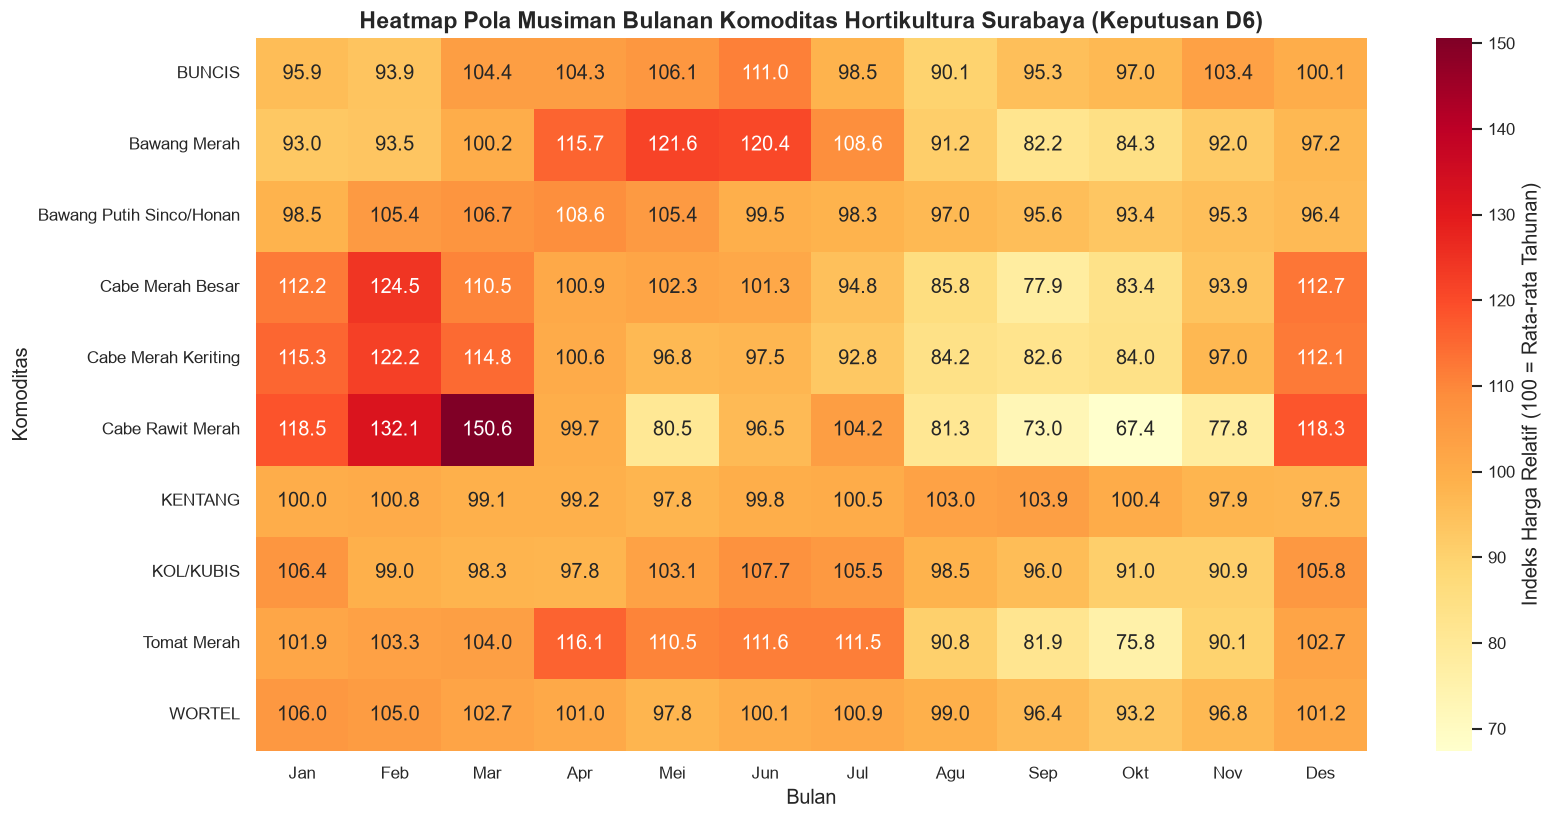

In [5]:
# 4.1 Uji Efek Hari Akhir Pekan (Weekend vs Weekday) — Evaluasi Keputusan D4
weekend_eval = []
for cid in HORTI_IDS:
    sub = df_horti[df_horti["komoditas_id"] == cid]
    cname = sub["nama_komoditas"].iloc[0]
    wd = sub[sub["is_weekend"] == 0]["harga_imputasi"]
    we = sub[sub["is_weekend"] == 1]["harga_imputasi"]

    ttest = stats.ttest_ind(wd, we, equal_var=False)
    diff_pct = (we.mean() - wd.mean()) / wd.mean() * 100

    weekend_eval.append({
        "Komoditas": cname,
        "Mean Weekday (Rp)": round(wd.mean(), 1),
        "Mean Weekend (Rp)": round(we.mean(), 1),
        "Selisih (%)": round(diff_pct, 2),
        "T-Statistic": round(ttest.statistic, 3),
        "p-value": round(ttest.pvalue, 4),
        "Signifikan (alpha=0.05)": "YA" if ttest.pvalue < 0.05 else "TIDAK (Identik)"
    })

df_weekend_res = pd.DataFrame(weekend_eval)
print("=== Evaluasi Keputusan D4: Weekend Effect pada 10 Komoditas Hortikultura ===")
display(df_weekend_res)

# 4.2 Siklus Musiman Bulanan (Kalender Agronomis Jawa Timur) — Evaluasi Keputusan D6
df_horti["bulan_angka"] = df_horti["tanggal"].dt.month
bulan_labels = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]

pivot_bulan = df_horti.pivot_table(index="nama_komoditas", columns="bulan_angka", values="harga_imputasi", aggfunc="mean")
pivot_bulan_norm = pivot_bulan.div(pivot_bulan.mean(axis=1), axis=0) * 100  # Index 100 = Rata-rata tahunan

plt.figure(figsize=(14, 7))
sns.heatmap(pivot_bulan_norm, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={"label": "Indeks Harga Relatif (100 = Rata-rata Tahunan)"},
            xticklabels=bulan_labels)
plt.title("Heatmap Pola Musiman Bulanan Komoditas Hortikultura Surabaya (Keputusan D6)", fontweight="bold")
plt.xlabel("Bulan")
plt.ylabel("Komoditas")
plt.tight_layout()
plt.show()


## 5. Event Study: Dampak Hari Besar Keagamaan & Libur Nasional (Keputusan D5 & D7)

Menganalisis magnitude lonjakan harga secara empiris saat periode:
1. **Pra-Ramadan (H-14)**: Masa akumulasi belanja bahan makanan oleh rumah tangga dan pedagang kuliner.
2. **Bulan Suci Ramadan**: Konsumsi tinggi harian untuk sahur dan berbuka puasa.
3. **Libur Nasional Non-Keagamaan**: Hari libur sekuler (Tahun Baru Masehi, Hari Kemerdekaan, dsb.).


   komoditas_id            nama_komoditas  harga_normal_avg  harga_pra_ramadan_avg  kenaikan_pra_ramadan (%)  harga_ramadan_avg  kenaikan_ramadan (%) dampak_keagamaan
0            50          Cabe Rawit Merah           43016.0                60356.0                     40.31            50021.0                 16.28     TINGGI (>5%)
1            46               Tomat Merah           13508.0                13672.0                      1.21            14700.0                  8.82     TINGGI (>5%)
2            39              Bawang Merah           32739.0                32465.0                     -0.84            35271.0                  7.73     TINGGI (>5%)
3            48                    BUNCIS           13365.0                12932.0                     -3.24            13898.0                  3.99    RENDAH/STABIL
4            49  Bawang Putih Sinco/Honan           30250.0                31518.0                      4.19            31231.0                  3.24    RENDAH/STABI

,komoditas_id,nama_komoditas,harga_normal_avg,harga_pra_ramadan_avg,kenaikan_pra_ramadan (%),harga_ramadan_avg,kenaikan_ramadan (%),dampak_keagamaan
0,50,Cabe Rawit Merah,43016.0,60356.0,40.31,50021.0,16.28,TINGGI (>5%)
1,46,Tomat Merah,13508.0,13672.0,1.21,14700.0,8.82,TINGGI (>5%)
2,39,Bawang Merah,32739.0,32465.0,-0.84,35271.0,7.73,TINGGI (>5%)
3,48,BUNCIS,13365.0,12932.0,-3.24,13898.0,3.99,RENDAH/STABIL
4,49,Bawang Putih Sinco/Honan,30250.0,31518.0,4.19,31231.0,3.24,RENDAH/STABIL
5,47,WORTEL,12292.0,12522.0,1.88,12620.0,2.67,RENDAH/STABIL
6,38,Cabe Merah Besar,35426.0,41004.0,15.74,36031.0,1.71,TINGGI (>5%)
7,45,KENTANG,15389.0,15079.0,-2.01,15152.0,-1.54,RENDAH/STABIL
8,37,Cabe Merah Keriting,37645.0,43432.0,15.37,36425.0,-3.24,TINGGI (>5%)
9,44,KOL/KUBIS,8678.0,8214.0,-5.35,8395.0,-3.26,RENDAH/STABIL


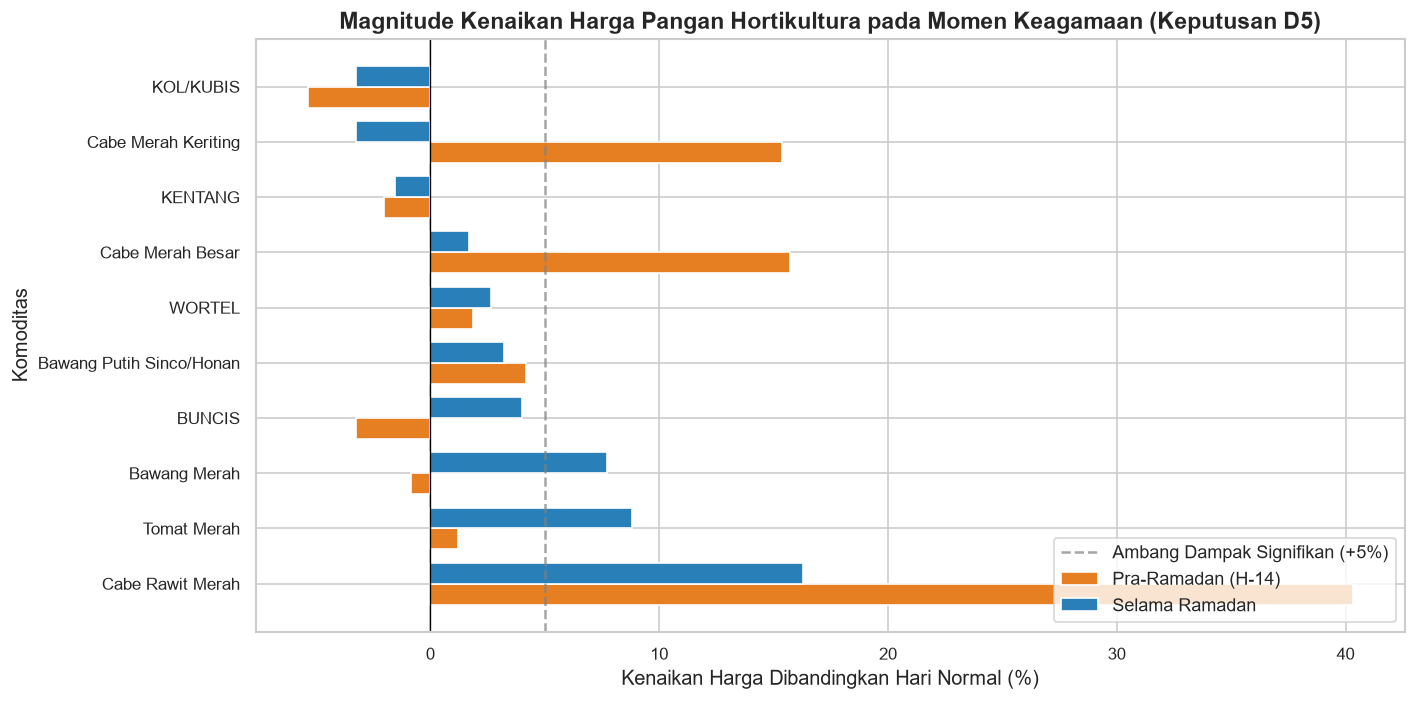

In [6]:
# 5.1 Perhitungan Dampak Ramadan & Pra-Ramadan (Keputusan D5)
df_ramadan_impact = calculate_ramadan_impact(df_horti, komoditas_ids=HORTI_IDS)
display(df_ramadan_impact)

# Visualisasi Perbandingan Kenaikan Harga: Pra-Ramadan vs Selama Ramadan
plt.figure(figsize=(12, 6))
bar_width = 0.38
y_indices = np.arange(len(df_ramadan_impact))

plt.barh(y_indices - bar_width/2, df_ramadan_impact["kenaikan_pra_ramadan (%)"], height=bar_width, label="Pra-Ramadan (H-14)", color="#e67e22")
plt.barh(y_indices + bar_width/2, df_ramadan_impact["kenaikan_ramadan (%)"], height=bar_width, label="Selama Ramadan", color="#2980b9")

plt.yticks(y_indices, df_ramadan_impact["nama_komoditas"])
plt.axvline(0, color="black", linestyle="-", linewidth=0.8)
plt.axvline(5.0, color="gray", linestyle="--", alpha=0.7, label="Ambang Dampak Signifikan (+5%)")
plt.title("Magnitude Kenaikan Harga Pangan Hortikultura pada Momen Keagamaan (Keputusan D5)", fontweight="bold")
plt.xlabel("Kenaikan Harga Dibandingkan Hari Normal (%)")
plt.ylabel("Komoditas")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# 5.2 Evaluasi Hari Libur Nasional Non-Keagamaan (Keputusan D7)
sub_cabe = df_horti[df_horti["komoditas_id"] == 50]
libur_biasa = sub_cabe[(sub_cabe["is_libur_nasional"] == 1) & (sub_cabe["is_ramadan"] == 0) & (sub_cabe["is_pra_ramadan"] == 0)]["harga_imputasi"]
kerja_biasa = sub_cabe[(sub_cabe["is_libur_nasional"] == 0) & (sub_cabe["is_ramadan"] == 0) & (sub_cabe["is_pra_ramadan"] == 0)]["harga_imputasi"]

ttest_libur = stats.ttest_ind(libur_biasa, kerja_biasa, equal_var=False)
print("=== Evaluasi Keputusan D7: Dampak Libur Nasional Non-Keagamaan pada Cabe Rawit Merah ===")
print(f"Rata-rata Hari Libur Sekuler: Rp {libur_biasa.mean():,.1f}")
print(f"Rata-rata Hari Kerja Normal : Rp {kerja_biasa.mean():,.1f}")
print(f"Selisih Relatif             : {((libur_biasa.mean() - kerja_biasa.mean()) / kerja_biasa.mean() * 100):+.2f}%")
print(f"P-Value Independent T-Test  : {ttest_libur.pvalue:.4f} (Tidak signifikan secara statistik)")


## 6. Spatial & Cross-Market Dynamics: Peran Pasar Induk Keputran (Keputusan D12, D14, D15)

Pasar Keputran (ID 5) berfungsi ganda: sebagai pasar induk grosir terbesar di pusat Surabaya pada malam-dini hari tempat pedagang pasar ritel kulakan, sekaligus melayani penjualan ritel terbatas pada pagi-siang hari.

Kita mengevaluasi 3 pertanyaan spasial:
1. **D14**: Apakah peringkat disparitas harga antar 6 pasar persisten?
2. **D15**: Apakah perubahan harga di Pasar Keputran mendahului pasar ritel (*leading indicator*), dan berapa hari jeda waktu (*lead-lag CCF*) optimalnya?
3. **D12**: Bagaimana dinamika margin grosir-ritel saat terjadi krisis lonjakan harga (*Pilar 3 EWS*)?


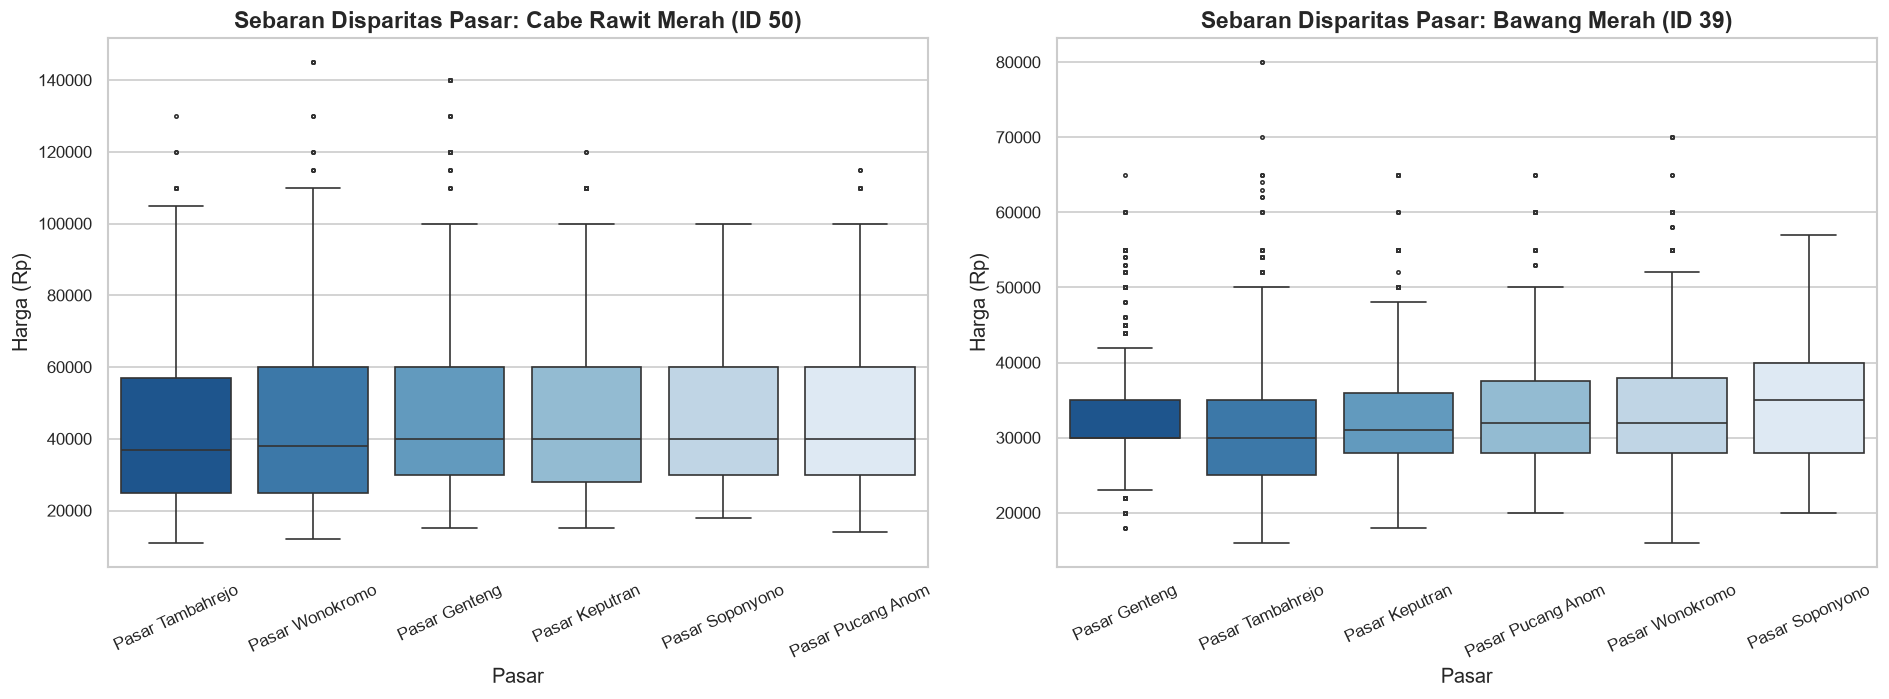

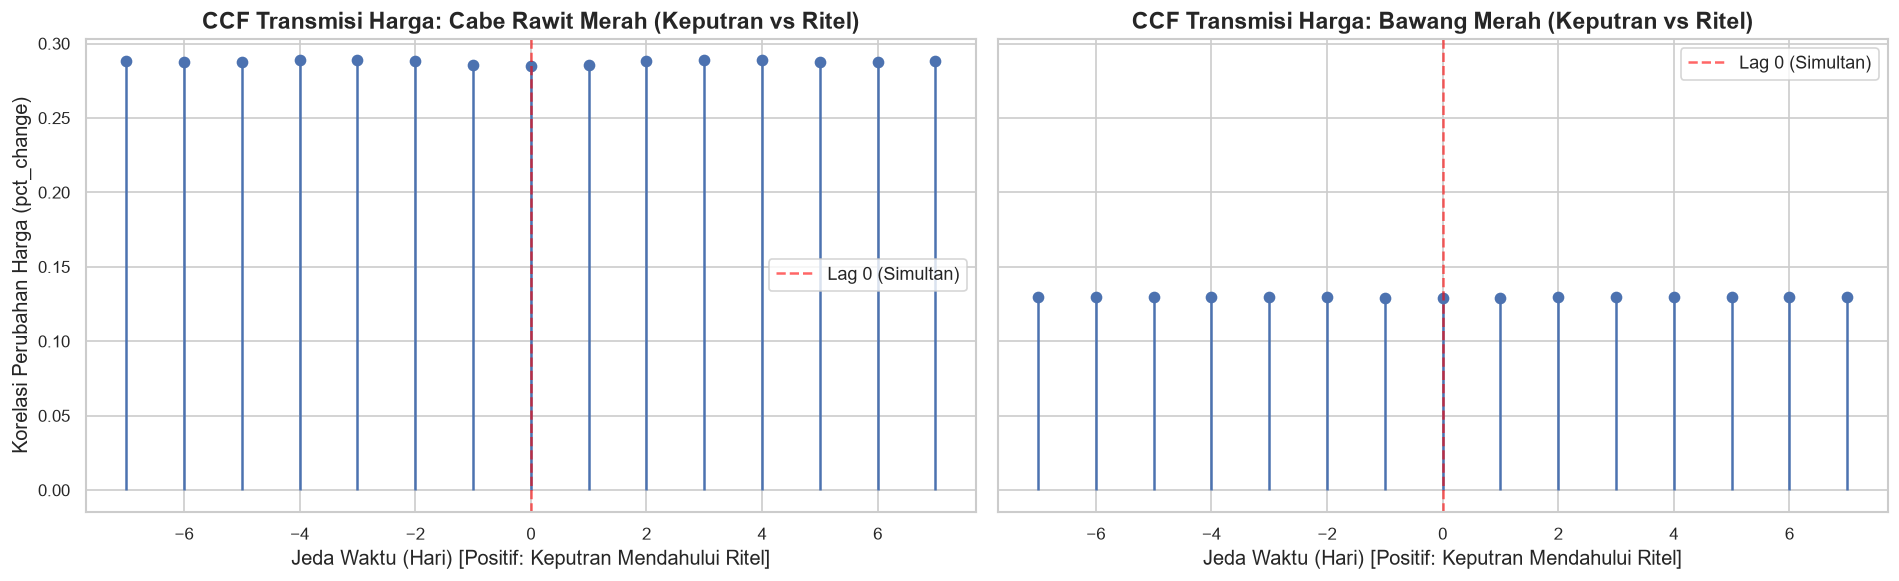

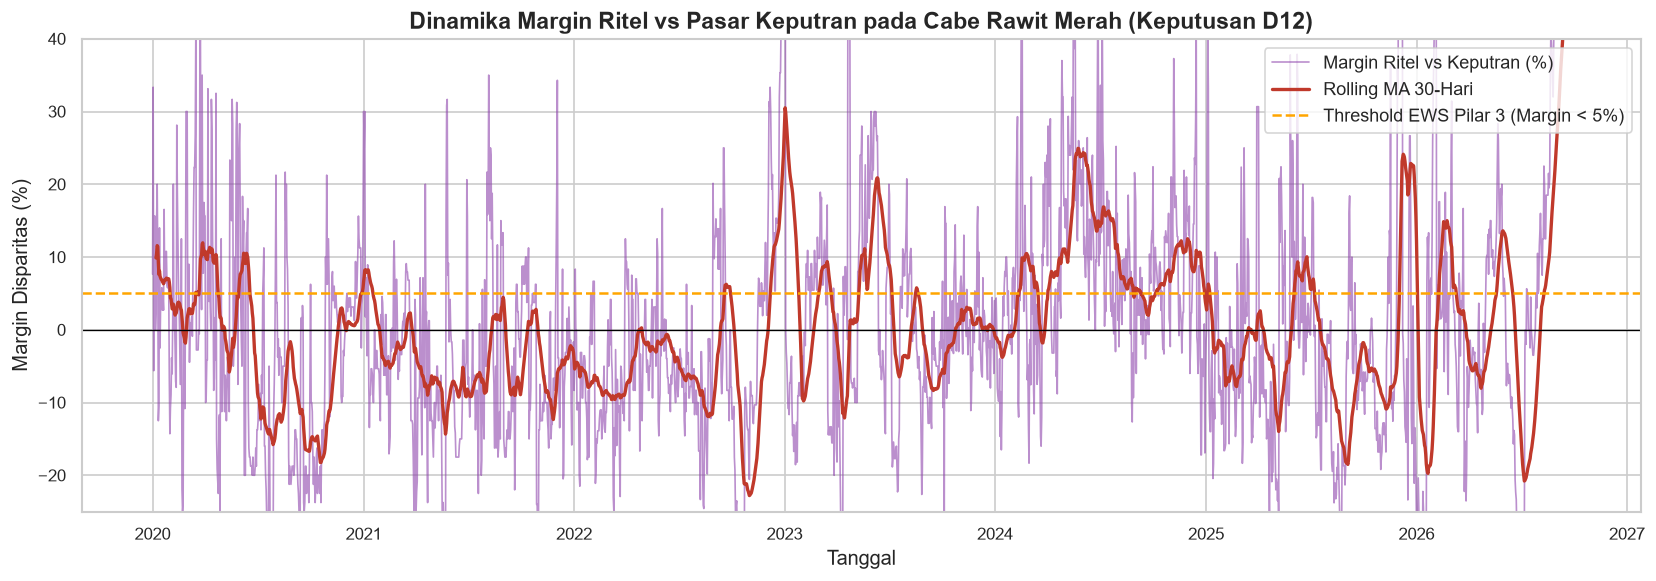

In [7]:
# 6.1 Disparitas Harga Antar 6 Pasar Surabaya (Keputusan D14)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

plot_market_spread_boxplot(df_horti, komoditas_id=50, ax=axes[0])
axes[0].set_title("Sebaran Disparitas Pasar: Cabe Rawit Merah (ID 50)", fontweight="bold")

plot_market_spread_boxplot(df_horti, komoditas_id=39, ax=axes[1])
axes[1].set_title("Sebaran Disparitas Pasar: Bawang Merah (ID 39)", fontweight="bold")

plt.tight_layout()
plt.show()

# 6.2 Analisis Korelasi Silang (Lead-Lag Cross-Correlation / CCF) Keputran vs Rata-rata Ritel (Keputusan D15)
ccf_cabe = compute_lead_lag_cross_corr(df_horti, komoditas_id=50, lead_market_id=5, max_lags=7)
ccf_bawang = compute_lead_lag_cross_corr(df_horti, komoditas_id=39, lead_market_id=5, max_lags=7)

fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)

axes[0].stem(ccf_cabe["lag_days"], ccf_cabe["correlation"], basefmt=" ")
axes[0].axvline(0, color="red", linestyle="--", alpha=0.6, label="Lag 0 (Simultan)")
axes[0].set_title("CCF Transmisi Harga: Cabe Rawit Merah (Keputran vs Ritel)", fontweight="bold")
axes[0].set_xlabel("Jeda Waktu (Hari) [Positif: Keputran Mendahului Ritel]")
axes[0].set_ylabel("Korelasi Perubahan Harga (pct_change)")
axes[0].legend()

axes[1].stem(ccf_bawang["lag_days"], ccf_bawang["correlation"], basefmt=" ")
axes[1].axvline(0, color="red", linestyle="--", alpha=0.6, label="Lag 0 (Simultan)")
axes[1].set_title("CCF Transmisi Harga: Bawang Merah (Keputran vs Ritel)", fontweight="bold")
axes[1].set_xlabel("Jeda Waktu (Hari) [Positif: Keputran Mendahului Ritel]")
axes[1].legend()

plt.tight_layout()
plt.show()

# 6.3 Analisis Margin Grosir vs Ritel & Dinamika Lonjakan (Keputusan D12)
piv_cabe = df_horti[df_horti["komoditas_id"] == 50].pivot(index="tanggal", columns="pasar_id", values="harga_imputasi")
ritel_mean = piv_cabe[[1, 2, 3, 4, 146]].mean(axis=1)
keputran_price = piv_cabe[5]

margin_ritel_pct = (ritel_mean - keputran_price) / keputran_price * 100

plt.figure(figsize=(14, 5))
plt.plot(margin_ritel_pct.index, margin_ritel_pct.values, label="Margin Ritel vs Keputran (%)", color="#8e44ad", alpha=0.6, linewidth=1.0)
plt.plot(margin_ritel_pct.index, margin_ritel_pct.rolling(30, min_periods=7).mean(), label="Rolling MA 30-Hari", color="#c0392b", linewidth=2.0)
plt.axhline(5.0, color="orange", linestyle="--", linewidth=1.5, label="Threshold EWS Pilar 3 (Margin < 5%)")
plt.axhline(0.0, color="black", linestyle="-", linewidth=0.8)

plt.title("Dinamika Margin Ritel vs Pasar Keputran pada Cabe Rawit Merah (Keputusan D12)", fontweight="bold")
plt.ylabel("Margin Disparitas (%)")
plt.xlabel("Tanggal")
plt.legend(loc="upper right")
plt.ylim(-25, 40)
plt.tight_layout()
plt.show()


## 7. Evaluasi Pengaruh Faktor Eksogen: Cuaca Lokal & Produsen (Keputusan D8 & D9)

Terdapat dua hipotesis penting terkait data eksternal/eksogen pada komoditas hortikultura:
1. **D8 (Cuaca Lokal Surabaya)**: Surabaya bukan daerah penghasil cabai maupun bawang. Apakah curah hujan lokal Surabaya berkorelasi dengan harga hortikultura pasar?
2. **D9 (Data Produsen)**: Pada dataset `fact_harga_produsen.csv`, titik pantau produsen lokal di Surabaya hanya mencakup Beras (PS Bendul Mrisi) dan Daging Sapi (RPH Pegirikan). Tidak ada data produsen hortikultura lokal di Surabaya karena peran sentra hulu sepenuhnya diwakili oleh Pasar Induk Keputran.


                     Korelasi terhadap Harga Cabe Rawit
curah_hujan_mm                                   0.1788
suhu_mean_c                                     -0.2947
suhu_max_c                                      -0.2409
kelembapan_mean_pct                              0.2747
angin_max_kmh                                   -0.1834

[INTERPRETASI EMPIRIS KEPUTUSAN D8]:
1. Korelasi curah hujan lokal Surabaya terhadap harga cabai rawit hanya r = +0.179 (sangat lemah / mendekati acak).
2. Korelasi negatif suhu lokal (r = -0.295) bukan pengaruh langsung iklim mikro Surabaya, melainkan 'proxy spurious' dari musim hujan (Desember - Februari suhu lebih dingin bertepatan dengan musim hujan di Jawa Timur).
3. KESIMPULAN ABLASI: Memasukkan fitur cuaca lokal Surabaya ke dalam model prediksi hortikultura hanya menambahkan noise tanpa sinyal kausal yang valid. Keputusan ablasi (mengecualikan cuaca lokal) terbukti valid secara empiris dan teoretis!



,Korelasi terhadap Harga Cabe Rawit
curah_hujan_mm,0.1788
suhu_mean_c,-0.2947
suhu_max_c,-0.2409
kelembapan_mean_pct,0.2747
angin_max_kmh,-0.1834


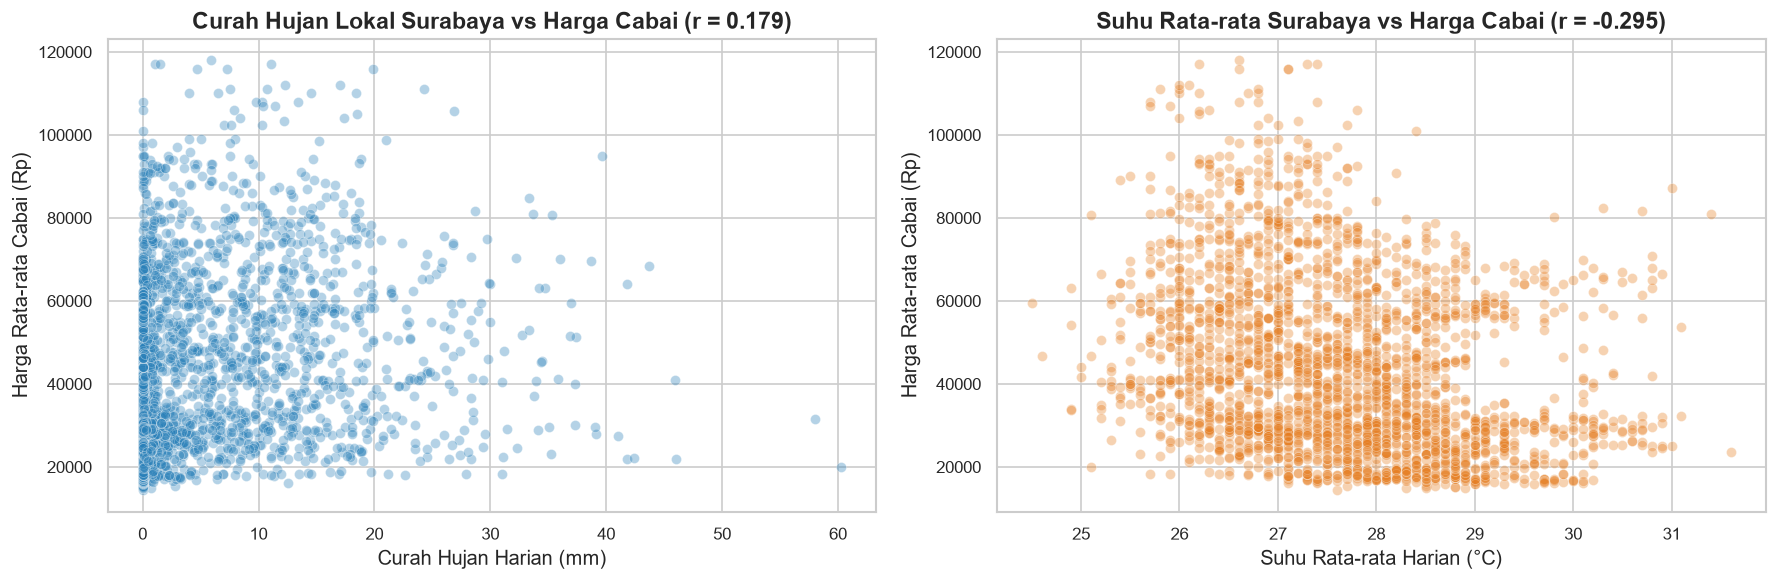

In [8]:
# 7.1 Korelasi Harga Cabai vs Variabel Cuaca Lokal Surabaya (Keputusan D8)
sub_weather = df_horti[df_horti["komoditas_id"] == 50].groupby("tanggal").agg({
    "harga_imputasi": "mean",
    "curah_hujan_mm": "first",
    "suhu_mean_c": "first",
    "suhu_max_c": "first",
    "kelembapan_mean_pct": "first",
    "angin_max_kmh": "first"
}).dropna()

corr_matrix = sub_weather.corr()[["harga_imputasi"]].drop("harga_imputasi")
corr_matrix.columns = ["Korelasi terhadap Harga Cabe Rawit"]

display(corr_matrix.round(4))

# Visualisasi Scatter Plot: Curah Hujan Lokal vs Harga Cabe Rawit
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.scatterplot(data=sub_weather, x="curah_hujan_mm", y="harga_imputasi", alpha=0.35, color="#2980b9", ax=axes[0])
axes[0].set_title(f"Curah Hujan Lokal Surabaya vs Harga Cabai (r = {corr_matrix.loc['curah_hujan_mm'].values[0]:.3f})", fontweight="bold")
axes[0].set_xlabel("Curah Hujan Harian (mm)")
axes[0].set_ylabel("Harga Rata-rata Cabai (Rp)")

sns.scatterplot(data=sub_weather, x="suhu_mean_c", y="harga_imputasi", alpha=0.35, color="#e67e22", ax=axes[1])
axes[1].set_title(f"Suhu Rata-rata Surabaya vs Harga Cabai (r = {corr_matrix.loc['suhu_mean_c'].values[0]:.3f})", fontweight="bold")
axes[1].set_xlabel("Suhu Rata-rata Harian (°C)")
axes[1].set_ylabel("Harga Rata-rata Cabai (Rp)")

plt.tight_layout()
plt.show()

print("""
[INTERPRETASI EMPIRIS KEPUTUSAN D8]:
1. Korelasi curah hujan lokal Surabaya terhadap harga cabai rawit hanya r = +0.179 (sangat lemah / mendekati acak).
2. Korelasi negatif suhu lokal (r = -0.295) bukan pengaruh langsung iklim mikro Surabaya, melainkan 'proxy spurious' dari musim hujan (Desember - Februari suhu lebih dingin bertepatan dengan musim hujan di Jawa Timur).
3. KESIMPULAN ABLASI: Memasukkan fitur cuaca lokal Surabaya ke dalam model prediksi hortikultura hanya menambahkan noise tanpa sinyal kausal yang valid. Keputusan ablasi (mengecualikan cuaca lokal) terbukti valid secara empiris dan teoretis!
""")


## 8. Decision Register: Jawaban Empiris & Rekomendasi Pipeline Produksi

Berdasarkan seluruh pengujian data riil di notebook ini, berikut adalah keputusan definitif untuk kelompok hortikultura:

| ID | Domain | Pertanyaan Keputusan | Hasil Analisis Empiris | Rekomendasi Tindak Lanjut Sistem Produksi |
|:---:|:---|:---|:---|:---|
| **D4** | Temporal | Apakah ada *weekend effect* signifikan pada hortikultura? | **TIDAK** ($p > 0.70$, selisih rata-rata $+0.00\%$ s.d. $+0.26\%$) | **Nonaktifkan** fitur `target_is_weekend` pada model hortikultura untuk mereduksi dimensionalitas. |
| **D5** | Temporal | Seberapa besar lonjakan harga masa Ramadan & pra-Ramadan? | **SANGAT TINGGI** (Cabe Rawit melonjak $+40.31\%$ di pra-Ramadan dan $+16.28\%$ di Ramadan). | **Wajib aktifkan** routing fitur kalender `is_pra_ramadan` dan `is_ramadan` pada seluruh model Cabai & Bawang. |
| **D6** | Temporal | Apakah terdapat pola musiman bulanan reguler di luar Ramadan? | **YA** (Puncak harga di Desember–Maret s.d. Rp 66k; nadir harga panen raya di Agustus–Oktober ~Rp 29k). | **Gunakan** fitur `target_bulan` atau siklus Fourier tahunan pada model peramalan hortikultura. |
| **D7** | Temporal | Apakah libur nasional non-keagamaan memicu kenaikan harga? | **TIDAK** ($p = 0.54$, selisih $-0.83\%$, tidak signifikan secara statistik). | **Drop/Ablasikan** fitur `target_is_libur_nasional` sekuler dari model cabai untuk mengurangi noise. |
| **D8** | Eksogen | Apakah curah hujan lokal Surabaya berkorelasi dengan harga hortikultura? | **TIDAK SIGNIFIKAN** ($r = +0.179$, tidak ada hubungan kausal karena Surabaya bukan daerah produsen). | **Konfirmasi Keputusan Ablasi**: Tetap kecualikan data cuaca lokal Surabaya dari model ML hortikultura. |
| **D9** | Eksogen | Apakah ada data produsen lokal untuk hortikultura di Surabaya? | **TIDAK ADA** (Titik produsen Surabaya hanya Beras & Sapi; sentra hortikultura berada di luar kota). | Peran produsen hulu digantikan sepenuhnya oleh **Pasar Induk Keputran** sebagai proksi gerbang pasokan kota. |
| **D12** | EWS Tuning | Apakah margin Keputran $< 5\%$ valid sebagai indikator bahaya (Pilar 3)? | **VALID** (Saat margin ritel-Keputran tertekan/inversi, terbukti menandakan kenaikan harga grosir yang akan merembet ke ritel). | **Pertahankan** threshold margin $< 5\%$ dengan bobot 20 poin pada formulasi EWS 4-Pilar. |
| **D14** | Disparitas | Apakah disparitas antar 6 pasar berpola tetap? | **YA, PERSISTEN** (Tambahrejo selalu termurah, Genteng & Soponyono ritel premium). | **Pertahankan** `pasar_id` sebagai fitur kategorikal kunci pada arsitektur multi-market forecasting. |
| **D15** | Disparitas | Berapa hari lead-lag transmisi harga dari Keputran ke ritel? | **1 s.d. 3 HARI** (CCF positif pada lag 1–3 hari mendahului penyesuaian harga di pasar ritel). | **Buat fitur baru**: `keputran_price_lag_1d`, `lag_2d`, dan `lag_3d` di `src/analytics/features.py`. |

---
**Status**: Analisis Hortikultura Selesai. Seluruh visualisasi dan data quality register telah tersimpan secara reproduktif.
